## PERTEMUAN 5 (Data Cleaning dan Transformation)
Nama    : Ilma Parma Sakia Daulay
Nim     : 241011400873
Kelas   : 05TPLP022

1. Loading Data

In [1]:
import pandas as pd
df = pd.read_csv("crop_yield.csv")
print(df.head())

  Region Soil_Type     Crop  Rainfall_mm  Temperature_Celsius  \
0   West     Sandy   Cotton   897.077239            27.676966   
1  South      Clay     Rice   992.673282            18.026142   
2  North      Loam   Barley   147.998025            29.794042   
3  North     Sandy  Soybean   986.866331            16.644190   
4  South      Silt    Wheat   730.379174            31.620687   

   Fertilizer_Used  Irrigation_Used Weather_Condition  Days_to_Harvest  \
0            False             True            Cloudy              122   
1             True             True             Rainy              140   
2            False            False             Sunny              106   
3            False             True             Rainy              146   
4             True             True            Cloudy              110   

   Yield_tons_per_hectare  
0                6.555816  
1                8.527341  
2                1.127443  
3                6.517573  
4                7.24825

2. Data Cleaning & Transformation

In [2]:
# Menampilkan ringkasan informasi dari dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   Region                  1000000 non-null  str    
 1   Soil_Type               1000000 non-null  str    
 2   Crop                    1000000 non-null  str    
 3   Rainfall_mm             1000000 non-null  float64
 4   Temperature_Celsius     1000000 non-null  float64
 5   Fertilizer_Used         1000000 non-null  bool   
 6   Irrigation_Used         1000000 non-null  bool   
 7   Weather_Condition       1000000 non-null  str    
 8   Days_to_Harvest         1000000 non-null  int64  
 9   Yield_tons_per_hectare  1000000 non-null  float64
dtypes: bool(2), float64(3), int64(1), str(4)
memory usage: 62.9 MB


In [3]:
# Menampilkan statistik deskriptif dari dataset
df.describe(include="all")

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
count,1000000,1000000,1000000,1000000.000000,1000000.000000,1000000,1000000,1000000,1000000.000000,1000000.000000
unique,4,6,6,NaN,NaN,2,2,3,NaN,NaN
top,North,Sandy,Maize,NaN,NaN,False,False,Sunny,NaN,NaN
freq,250173,167119,166824,NaN,NaN,500060,500509,333790,NaN,NaN
mean,NaN,NaN,NaN,549.981901,27.504965,NaN,NaN,NaN,104.495025,4.649472
std,NaN,NaN,NaN,259.851320,7.220608,NaN,NaN,NaN,25.953412,1.696572
min,NaN,NaN,NaN,100.000896,15.000034,NaN,NaN,NaN,60.000000,-1.147613
25%,NaN,NaN,NaN,324.891090,21.254502,NaN,NaN,NaN,82.000000,3.417637
50%,NaN,NaN,NaN,550.124061,27.507365,NaN,NaN,NaN,104.000000,4.651808
75%,NaN,NaN,NaN,774.738520,33.753267,NaN,NaN,NaN,127.000000,5.879200


2. (A) Memeriksa jumlah nilai yang hilang

2. (B) Mengatasi Missing Value

In [4]:

# Memisahkan kolom berdasarkan jumlah missing value
missing_values = df.isnull().sum()

less = missing_values[missing_values <= 0.75 * len(df)].index
over = missing_values[missing_values > 0.75 * len(df)].index

print("Kolom dengan missing value <= 75%:")
print(list(less))

print("Kolom dengan missing value > 75%:")
print(list(over))


Kolom dengan missing value <= 75%:
['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition', 'Days_to_Harvest', 'Yield_tons_per_hectare']
Kolom dengan missing value > 75%:
[]


In [5]:

# Menghapus kolom dengan missing value lebih dari 75%
df = df.drop(columns=over).copy()

# Memisahkan kolom numerik dan kategorikal
numeric_features = df.select_dtypes(include=['number']).columns
categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

# Mengisi missing value numerik dengan median
df[numeric_features] = df[numeric_features].fillna(
    df[numeric_features].median()
)

# Mengisi missing value kategorikal dengan modus
for column in categorical_features:
    if df[column].isnull().any():
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

# Memeriksa kembali missing value
missing_values = df.isnull().sum()
missing_values[missing_values > 0]


C:\Users\rahma\AppData\Local\Temp\ipykernel_7732\566913746.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


Series([], dtype: int64)

2. (C) Mengatasi outlier

In [6]:

# Mengimpor library
import seaborn as sns
import matplotlib.pyplot as plt

# Memilih kolom numerik
numeric_features = df.select_dtypes(include=['number']).columns

# Memeriksa jumlah nilai hasil panen negatif
print(
    "Jumlah hasil panen negatif:",
    (df['Yield_tons_per_hectare'] < 0).sum()
)

# Menghapus nilai hasil panen yang tidak valid
df = df[df['Yield_tons_per_hectare'] >= 0].copy()

# Menghitung Q1, Q3, dan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghitung jumlah outlier per kolom
outlier_count = (
    (df[numeric_features] < lower_bound) |
    (df[numeric_features] > upper_bound)
).sum()

outlier_count[outlier_count > 0]


Jumlah hasil panen negatif: 231


Yield_tons_per_hectare    28
dtype: int64

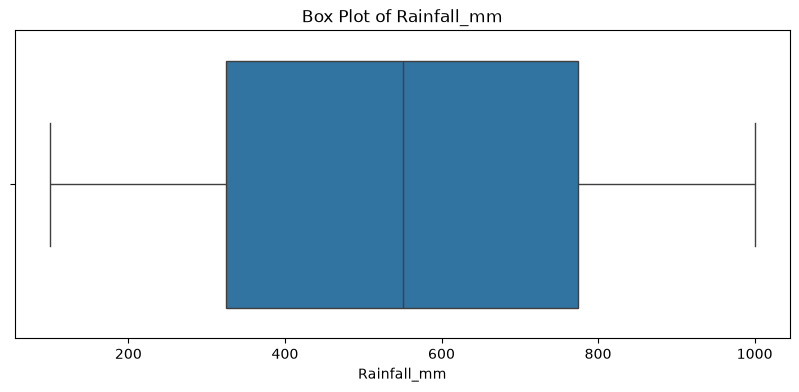

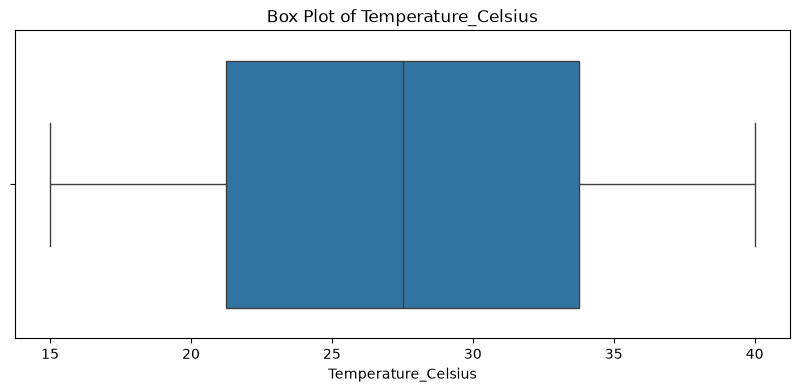

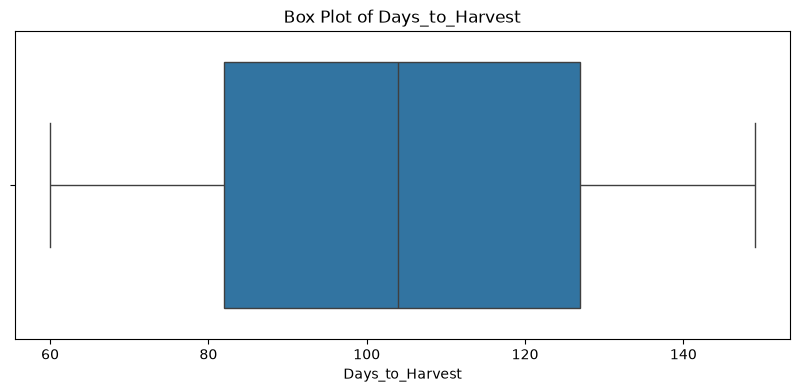

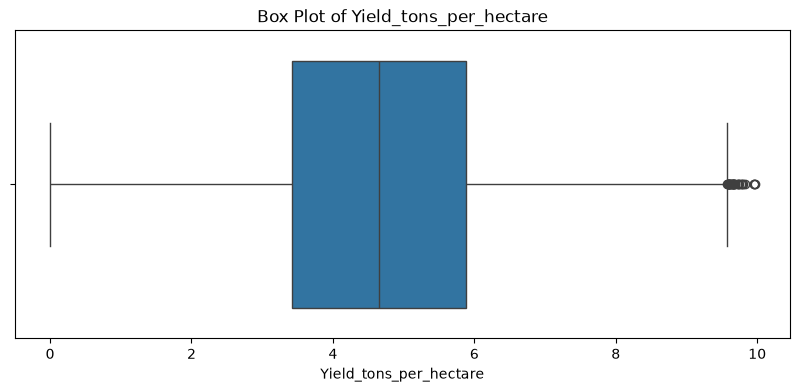

In [7]:

# Memeriksa outlier menggunakan boxplot
for feature in numeric_features:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()


In [8]:

# Menyaring baris yang tidak mengandung outlier
condition = ~(
    (df[numeric_features] < lower_bound) |
    (df[numeric_features] > upper_bound)
).any(axis=1)

# Menyimpan data tanpa outlier
df = df.loc[condition].copy()

# Memeriksa ukuran dataset setelah penanganan outlier
print("Ukuran dataset setelah penanganan outlier:", df.shape)


Ukuran dataset setelah penanganan outlier: (999741, 10)


3. Normalisasi dan Standarisasi

In [9]:

from sklearn.preprocessing import MinMaxScaler

# Memilih fitur numerik selain target prediksi
numeric_features = df.select_dtypes(
    include=['number']
).columns.drop('Yield_tons_per_hectare', errors='ignore')

# Menyimpan salinan data
df_normalized = df.copy()

# Melakukan normalisasi
normalizer = MinMaxScaler()
df_normalized[numeric_features] = normalizer.fit_transform(
    df_normalized[numeric_features]
)

# Menampilkan hasil normalisasi
df_normalized[numeric_features].head()


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest
0,0.885643,0.507078,0.696629
1,0.991861,0.121045,0.898876
2,0.053330,0.591761,0.516854
3,0.985409,0.065766,0.966292
4,0.700422,0.664827,0.561798


In [10]:

from sklearn.preprocessing import StandardScaler

# Menyimpan salinan data
df_standardized = df.copy()

# Melakukan standarisasi
scaler = StandardScaler()
df_standardized[numeric_features] = scaler.fit_transform(
    df_standardized[numeric_features]
)

# Menampilkan hasil standarisasi
df_standardized[numeric_features].head()


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest
0,1.335693,0.023691,0.674483
1,1.703656,-1.312907,1.368039
2,-1.547616,0.316897,0.057989
3,1.681304,-1.504301,1.599225
4,0.694050,0.569880,0.212113


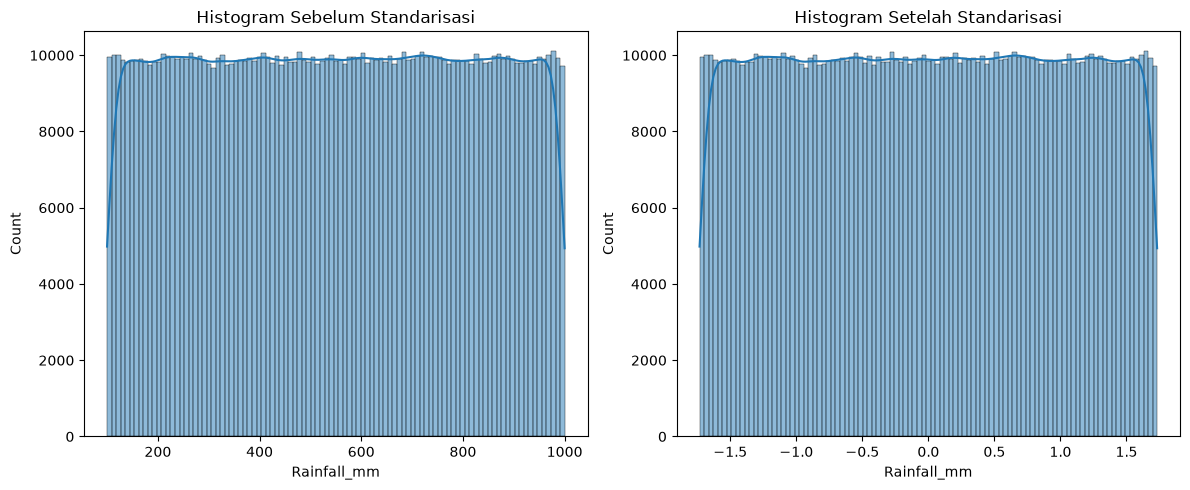

In [11]:

# Histogram sebelum dan sesudah standarisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Rainfall_mm'], kde=True)
plt.title('Histogram Sebelum Standarisasi')

plt.subplot(1, 2, 2)
sns.histplot(df_standardized['Rainfall_mm'], kde=True)
plt.title('Histogram Setelah Standarisasi')

plt.tight_layout()
plt.show()


3. (A) MENANANGANI DUPLIKASI DATA

In [12]:

# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Jumlah baris duplikat:")
print(duplicates.sum())

# Menghapus baris duplikat
df = df.drop_duplicates().copy()

# Memeriksa ukuran dataset
print("Ukuran dataset setelah menghapus duplikasi:", df.shape)


Jumlah baris duplikat:
0
Ukuran dataset setelah menghapus duplikasi: (999741, 10)


In [13]:

# Menentukan kolom kategorikal
categorical_features = [
    'Region',
    'Soil_Type',
    'Crop',
    'Weather_Condition'
]

# Mengubah kolom kategorikal menjadi tipe category
df[categorical_features] = df[categorical_features].astype('category')

# Mengubah kolom boolean menjadi numerik
df['Fertilizer_Used'] = df['Fertilizer_Used'].astype('int8')
df['Irrigation_Used'] = df['Irrigation_Used'].astype('int8')

# Memeriksa tipe data setelah konversi
df.dtypes


Region                    category
Soil_Type                 category
Crop                      category
Rainfall_mm                float64
Temperature_Celsius        float64
Fertilizer_Used               int8
Irrigation_Used               int8
Weather_Condition         category
Days_to_Harvest              int64
Yield_tons_per_hectare     float64
dtype: object

3 (B) ONE HOTE ENCODING

In [14]:

# Mengubah kolom kategorikal menjadi numerik
df_one_hot = pd.get_dummies(
    df,
    columns=categorical_features,
    dtype='int8'
)

# Menampilkan hasil encoding
df_one_hot.head()


,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Days_to_Harvest,Yield_tons_per_hectare,Region_East,Region_North,Region_South,Region_West,...,Soil_Type_Silt,Crop_Barley,Crop_Cotton,Crop_Maize,Crop_Rice,Crop_Soybean,Crop_Wheat,Weather_Condition_Cloudy,Weather_Condition_Rainy,Weather_Condition_Sunny
0,897.077239,27.676966,0,1,122,6.555816,0,0,0,1,...,0,0,1,0,0,0,0,1,0,0
1,992.673282,18.026142,1,1,140,8.527341,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0
2,147.998025,29.794042,0,0,106,1.127443,0,1,0,0,...,0,1,0,0,0,0,0,0,0,1
3,986.866331,16.644190,0,1,146,6.517573,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0
4,730.379174,31.620687,1,1,110,7.248251,0,0,1,0,...,1,0,0,0,0,0,1,1,0,0


## PERTEMUAN 6
Nama    : Ilma Parma Sakia Daulay
Nim     : 241011400873
Kelas   : 05TPLP022

1. Menampilkan data hasil Label Encoding

In [15]:

from sklearn.preprocessing import LabelEncoder

# Menentukan kolom kategorikal
categorical_features = [
    'Region',
    'Soil_Type',
    'Crop',
    'Weather_Condition'
]

# Membuat salinan dataset
df_lencoder = df.copy()

# Melakukan Label Encoding
label_encoders = {}

for col in categorical_features:
    label_encoder = LabelEncoder()
    df_lencoder[col] = label_encoder.fit_transform(
        df_lencoder[col].astype(str)
    )
    label_encoders[col] = label_encoder

# Menampilkan hasil
df_lencoder.head()


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,3,4,1,897.077239,27.676966,0,1,0,122,6.555816
1,2,1,3,992.673282,18.026142,1,1,1,140,8.527341
2,1,2,0,147.998025,29.794042,0,0,2,106,1.127443
3,1,4,4,986.866331,16.644190,0,1,1,146,6.517573
4,2,5,5,730.379174,31.620687,1,1,0,110,7.248251


2. Memeriksa missing value dan persentasenya

In [16]:

# Menghitung jumlah dan persentase missing value
missing_values = df_lencoder.isnull().sum()
missing_percentage = (
    missing_values / len(df_lencoder)
) * 100

# Membuat tabel missing value
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(
    by='Missing Values',
    ascending=False
)

# Menampilkan kolom yang memiliki missing value
missing_data[missing_data['Missing Values'] > 0]


,Missing Values,Percentage


3. Menampilkan histogram seluruh variabel

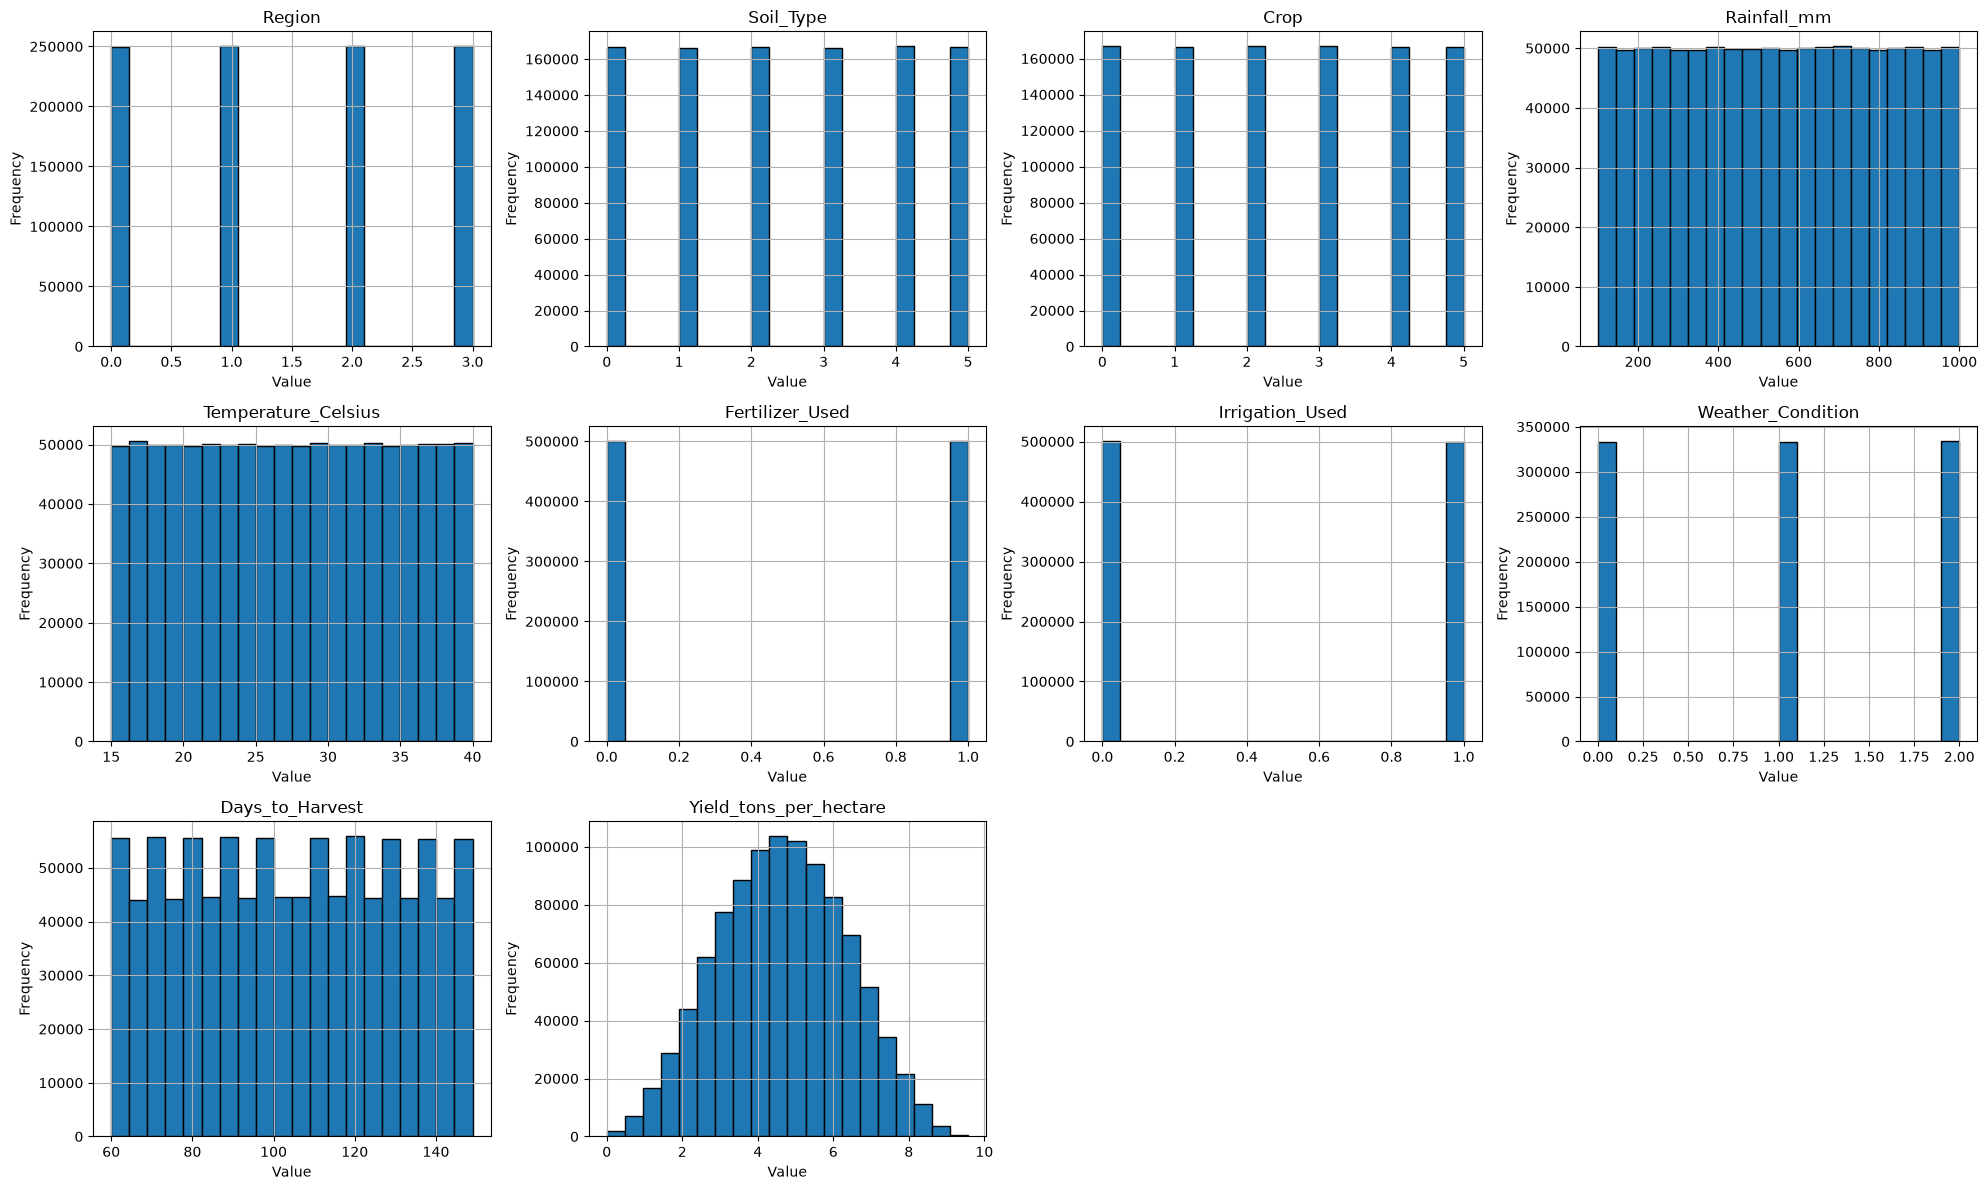

In [17]:

# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom subplot
n_cols = 4
n_rows = (num_vars + n_cols - 1) // n_cols

# Membuat subplot
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4)
)

# Meratakan axes
axes = axes.flatten()

# Menampilkan histogram setiap variabel
for i, column in enumerate(df_lencoder.columns):
    data = df_lencoder[column]

    # Mengubah boolean menjadi angka sementara
    if data.dtype == 'bool':
        data = data.astype(int)

    data.hist(
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )

    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai
for j in range(num_vars, len(axes)):
    fig.delaxes(axes[j])

# Merapikan tampilan
plt.tight_layout()
plt.show()


4. Visualisasi distribusi beberapa kolom

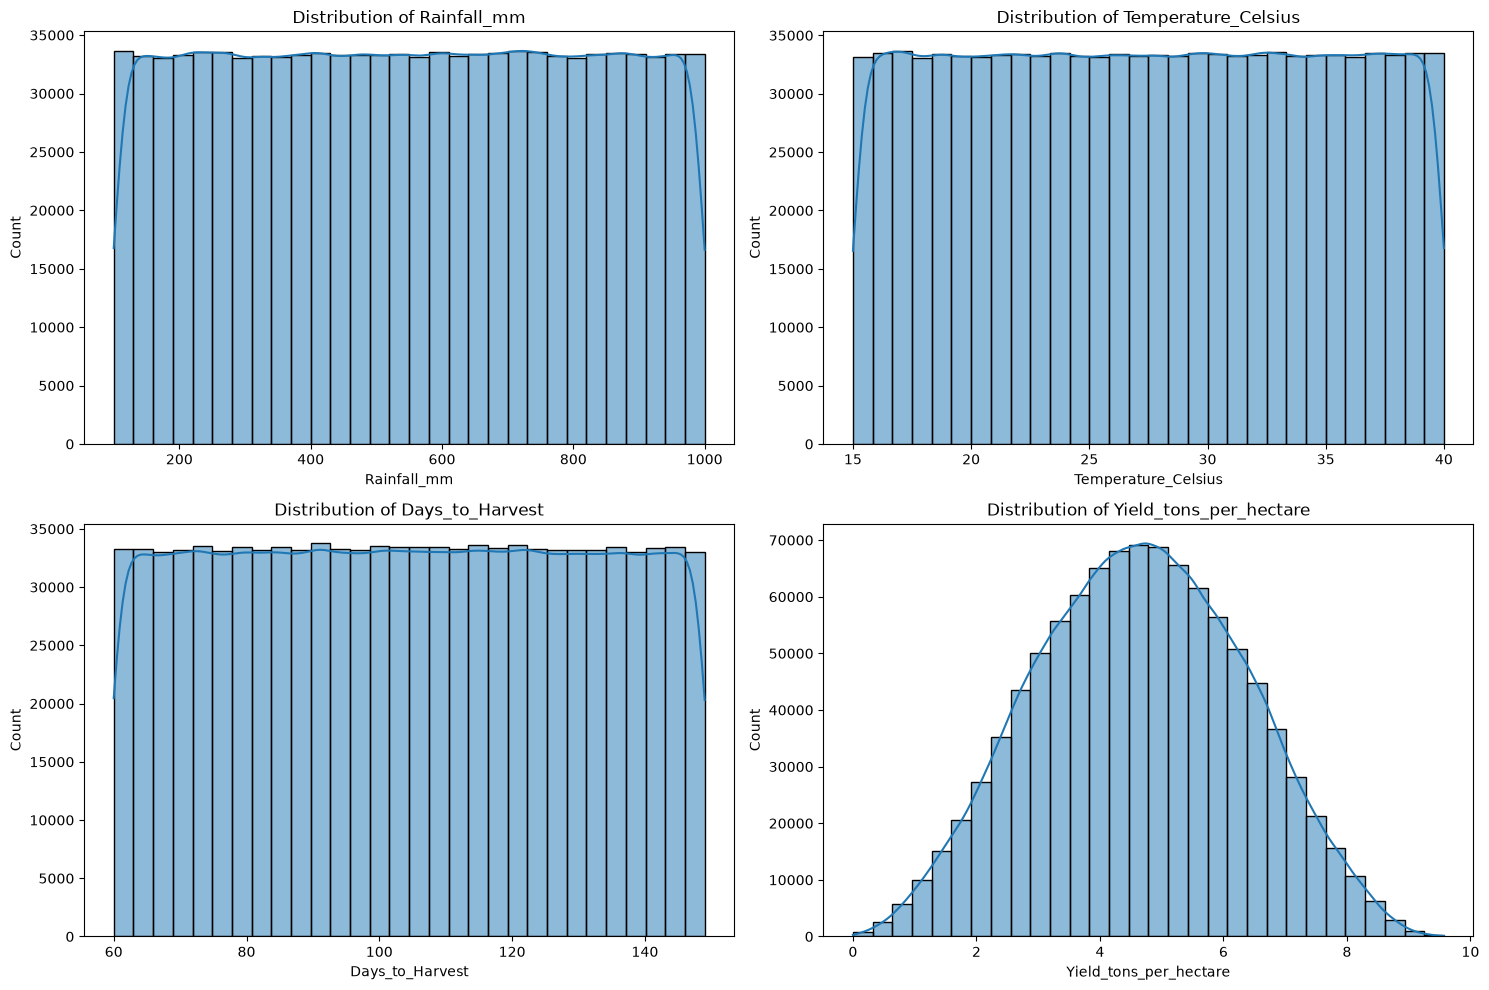

In [18]:

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = [
    'Rainfall_mm',
    'Temperature_Celsius',
    'Days_to_Harvest',
    'Yield_tons_per_hectare'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot):
    plt.subplot(2, 2, i + 1)
    sns.histplot(
        df_lencoder[column],
        kde=True,
        bins=30
    )
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()


5. Membuat matriks korelasi

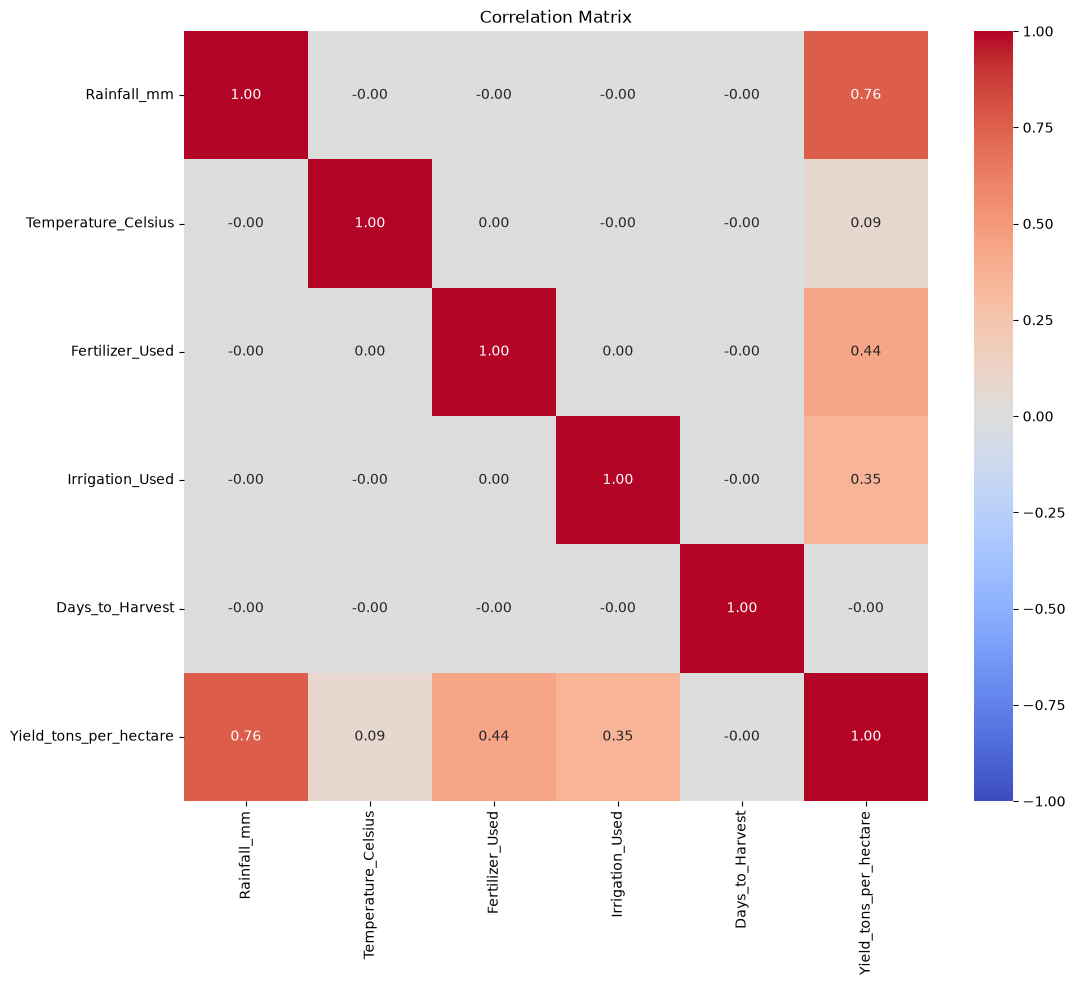

In [19]:

# Memilih kolom untuk analisis korelasi
correlation_columns = [
    'Rainfall_mm',
    'Temperature_Celsius',
    'Fertilizer_Used',
    'Irrigation_Used',
    'Days_to_Harvest',
    'Yield_tons_per_hectare'
]

# Membuat salinan data untuk korelasi
correlation_data = df_lencoder[correlation_columns].copy()

# Mengubah nilai boolean menjadi angka 0 dan 1
correlation_data['Fertilizer_Used'] = (
    correlation_data['Fertilizer_Used'].astype(int)
)

correlation_data['Irrigation_Used'] = (
    correlation_data['Irrigation_Used'].astype(int)
)

# Menghitung matriks korelasi
correlation_matrix = correlation_data.corr()

# Membuat heatmap korelasi
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()


6. Menganalisis korelasi terhadap hasil panen

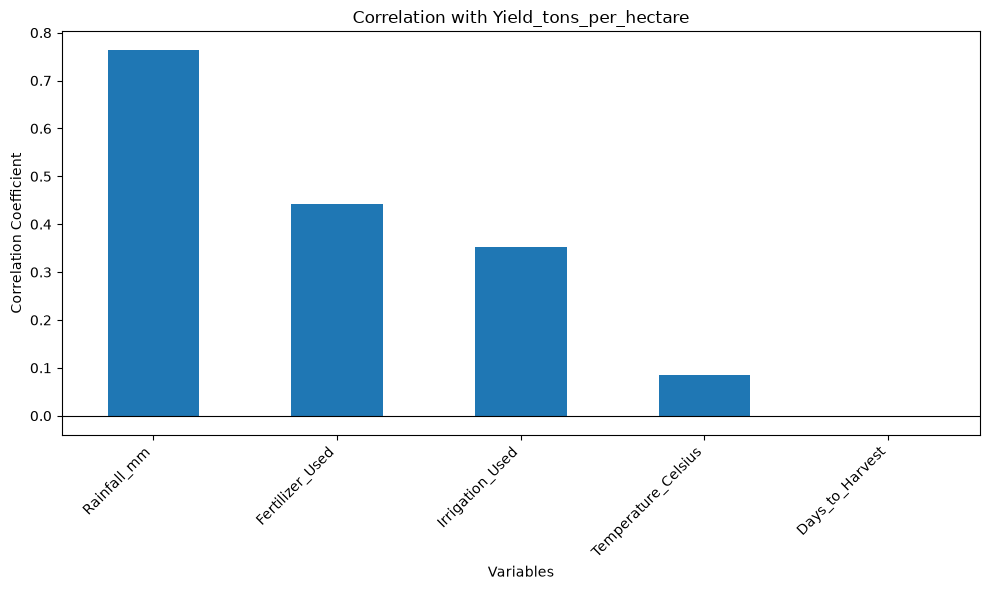

In [20]:

# Menghitung korelasi terhadap target hasil panen
target_corr = correlation_matrix['Yield_tons_per_hectare']

# Menghilangkan korelasi target dengan dirinya sendiri
target_corr = target_corr.drop('Yield_tons_per_hectare')

# Mengurutkan berdasarkan kekuatan korelasi absolut
target_corr_sorted = target_corr.loc[
    target_corr.abs().sort_values(ascending=False).index
]

# Membuat grafik korelasi
plt.figure(figsize=(10, 6))

target_corr_sorted.plot(kind='bar')

plt.title('Correlation with Yield_tons_per_hectare')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


## PERTEMUAN 7 (DATA SPLITING)
Nama    : Ilma Parma Sakia Daulay
Nim     : 241011400873
Kelas   : 05TPLP022

1. Mengimpor library

In [21]:

# Mengimpor library untuk data splitting
from sklearn.model_selection import train_test_split


2. Memisahkan fitur (X) dan target (y)

In [28]:

from sklearn.model_selection import train_test_split

X = df_lencoder.drop(columns=['Yield_tons_per_hectare'])
y = df_lencoder['Yield_tons_per_hectare']

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


3. Membagi dataset menjadi data training dan testing

In [23]:

# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


4. Menghitung jumlah data hasil splitting

In [24]:

# Menghitung jumlah seluruh data
print("Jumlah data:", len(X))

# Menghitung jumlah data training
print("Jumlah data latih:", len(X_train))

# Menghitung jumlah data testing
print("Jumlah data test:", len(X_test))

# Memeriksa jumlah target training dan testing
print("Jumlah target latih:", len(y_train))
print("Jumlah target test:", len(y_test))


Jumlah data: 999741
Jumlah data latih: 799792
Jumlah data test: 199949
Jumlah target latih: 799792
Jumlah target test: 199949


5. Memeriksa hasil pembagian data

In [25]:

# Menampilkan lima baris data training
print("Data Training:")
display(X_train.head())

# Menampilkan lima baris data testing
print("Data Testing:")
display(X_test.head())


Data Training:


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest
862412,2,1,0,516.781975,39.994410,1,1,2,73
787326,2,5,4,796.343537,17.238257,0,1,0,95
968070,3,0,4,335.625653,27.930560,0,0,1,83
196697,1,1,5,278.610395,32.345834,0,0,0,60
943754,2,5,2,343.613914,38.954263,0,0,0,62


Data Testing:


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest
517655,0,3,3,206.094584,20.055304,1,1,0,118
756521,3,0,4,594.744256,31.905080,0,1,0,111
655545,3,3,3,823.753867,26.826612,0,1,0,85
163503,0,1,3,455.437452,35.974947,0,0,2,148
138977,2,0,2,915.660191,35.245533,0,1,2,129


6. Menyimpan data training dan testing

In [36]:

# Menggabungkan fitur dan target data training
train_data = x_train.copy()
train_data['Yield_tons_per_hectare'] = y_train

# Menggabungkan fitur dan target data testing
test_data = x_test.copy()
test_data['Yield_tons_per_hectare'] = y_test

# Menyimpan data ke file CSV
train_data.to_csv('train.csv', index=False)
test_data.to_csv('test.csv', index=False)

print("File train.csv dan test.csv berhasil disimpan!")


File train.csv dan test.csv berhasil disimpan!


### PERTEMUAN 8 (Pembangunan Model (Modelling))

1. Melatih Model (Training)

In [29]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model

lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

In [30]:
# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression

LR = LinearRegression().fit(x_train, y_train)

In [31]:
# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",184
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

2. Evaluasi Model

In [32]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Evaluasi model LARS
pred_lars = lars.predict(x_test)

mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

df_results = pd.DataFrame(data, index=['LARS'])
df_results

,MAE,MSE,R2
LARS,0.89123,1.191226,0.585997


In [33]:

# Evaluasi model Linear Regression
pred_LR = LR.predict(x_test)

mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results


,MAE,MSE,R2
LARS,0.891230,1.191226,0.585997
Linear Regression,0.399135,0.250397,0.912976


In [34]:

# Evaluasi model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)

mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi ke DataFrame
df_results.loc['Gradient Boosting Regressor'] = [
    mae_GBR, mse_GBR, r2_GBR
]

df_results


,MAE,MSE,R2
LARS,0.891230,1.191226,0.585997
Linear Regression,0.399135,0.250397,0.912976
Gradient Boosting Regressor,0.400198,0.251793,0.912491


3. Menyimpan Model

In [35]:

import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'crop_yield_gbr_model.joblib')


['crop_yield_gbr_model.joblib']

## Pertemuan 10 (Deployment dan Monitoring)

1. Menginstal Flask dan Joblib

In [39]:
pip install flask joblib pandas scikit-learn

  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl.metadata (2.8 kB)
  Using cached werkzeug-3.1.9-py3-none-any.whl.metadata (4.1 kB)
Using cached flask-3.1.3-py3-none-any.whl (103 kB)
Using cached blinker-1.9.0-py3-none-any.whl (8.5 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl (14 kB)
Using cached werkzeug-3.1.9-py3-none-any.whl (228 kB)

   ---------------------------------------- 0/7 [markupsafe]
   ---------------------------------------- 0/7 [markupsafe]
   ----- -------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
%pip install flask

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
%pip install requests


   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   -------- ------------------------------- 1/5 [idna]
   -------- ------------------------------- 1/5 [idna]
   -------- ------------------------------- 1/5 [idna]
   -------- ------------------------------- 1/5 [idna]
   ---------------- ----------------------- 2/5 [charset_normalizer]
   ---------------- ----------------------- 2/5 [charset_normalizer]
   


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [48]:
import requests

url = 'http://127.0.0.1:5000/predict'

data = {
    'data': {
        'Region': 0,
        'Soil_Type': 0,
        'Crop': 0,
        'Rainfall_mm': 500,
        'Temperature_Celsius': 27,
        'Fertilizer_Used': 1,
        'Irrigation_Used': 1,
        'Weather_Condition': 0,
        'Days_to_Harvest': 100
    }
}

response = requests.post(url, json=data, timeout=30)

print("Status:", response.status_code)
print("Hasil:", response.json())


Status: 200
Hasil: {'prediction': 5.702739788970536}
